# 07 - IA : regrouper les séismes en zones avec KMeans

Dans cette étape j'utilise le KMeans de Spark MLlib pour regrouper automatiquement les séismes de magnitude 4.5 ou plus en 10 zones.

Le KMeans ne connaît rien à la géologie : il regroupe juste les points qui sont proches les uns des autres. Je veux voir si les zones qu'il trouve correspondent aux grandes régions sismiques (Japon, Indonésie, Andes...).

C'est un apprentissage non supervisé : je ne lui donne pas de bonnes réponses, il trouve les groupes tout seul.

## 1. J'ouvre la SparkSession et je définis les chemins

In [1]:
from pathlib import Path
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = SparkSession.builder.appName("07_kmeans").getOrCreate()

CHEMIN_CARTE = "/lakehouse/gold/gold_carte"        # les séismes >= 4.5 (notebook 06)
CHEMIN_ZONES = "/lakehouse/gold/gold_zones"        # la nouvelle table gold que je vais créer
DOSSIER_SERVING = Path("/work/data/serving")
K = 10   # nombre de zones, je le choisis à la main

print("Application :", spark.sparkContext.appName)

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/12 17:39:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Application : 07_kmeans


## 2. Je lis la table gold_carte

In [2]:
carte = spark.read.format("delta").load(CHEMIN_CARTE)

print("Séismes de magnitude >= 4.5 :", carte.count(), "(attendu : 74362)")
carte.select("id", "latitude", "longitude", "profondeur", "magnitude", "lieu").show(3, truncate=False)

26/11/12 17:40:35 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Séismes de magnitude >= 4.5 : 74362 (attendu : 74362)


+------------+--------+---------+----------+---------+-------------------------------+
|id          |latitude|longitude|profondeur|magnitude|lieu                           |
+------------+--------+---------+----------+---------+-------------------------------+
|ak02027j9fgu|57.5151 |-156.0645|100.7     |4.9      |79 km E of Ugashik, Alaska     |
|ak0203l91abz|66.2877 |-157.2513|8.6       |5.0      |67 km S of Shungnak, Alaska    |
|ak0206hgz4pc|54.6173 |-156.7715|8.5       |4.7      |208 km SE of Perryville, Alaska|
+------------+--------+---------+----------+---------+-------------------------------+
only showing top 3 rows



## 3. Pourquoi je ne donne pas directement la latitude et la longitude au KMeans
Le KMeans calcule des distances. Avec la longitude, il y a un piège : 179° et -179° sont presque au même endroit (à côté des Fidji), mais pour le KMeans la différence serait de 358°.

Je vérifie ça sur 2 points de test avant de faire le vrai calcul.

In [3]:
test = spark.createDataFrame(
    [("point A (Fidji, 179°)", -18.0, 179.0), ("point B (Fidji, -179°)", -18.0, -179.0)],
    ["point", "latitude", "longitude"],
)
test.show(truncate=False)

print("Différence de longitude vue par le KMeans :", 179.0 - (-179.0), "degrés")
print("Alors qu'en vrai les 2 points sont à environ 2 degrés l'un de l'autre")

+----------------------+--------+---------+
|point                 |latitude|longitude|
+----------------------+--------+---------+
|point A (Fidji, 179°) |-18.0   |179.0    |
|point B (Fidji, -179°)|-18.0   |-179.0   |
+----------------------+--------+---------+

Différence de longitude vue par le KMeans : 358.0 degrés
Alors qu'en vrai les 2 points sont à environ 2 degrés l'un de l'autre


## 4. Je transforme chaque séisme en position (x, y, z) sur une sphère
Au lieu de latitude et longitude, je place chaque séisme sur une boule de rayon 1 :
- x = cos(latitude) × cos(longitude)
- y = cos(latitude) × sin(longitude)
- z = sin(latitude)

Comme ça la distance entre deux points est la vraie distance sur la Terre, et 179° et -179° restent voisins.

In [4]:
def ajouter_xyz(df):
    lat = F.radians("latitude")    # les fonctions cos et sin travaillent en radians
    lon = F.radians("longitude")
    return (
        df.withColumn("x", F.cos(lat) * F.cos(lon))
          .withColumn("y", F.cos(lat) * F.sin(lon))
          .withColumn("z", F.sin(lat))
    )

# je refais le test : les 2 points de test doivent maintenant être très proches
test_xyz = ajouter_xyz(test).collect()
a, b = test_xyz[0], test_xyz[1]
distance = ((a["x"] - b["x"]) ** 2 + (a["y"] - b["y"]) ** 2 + (a["z"] - b["z"]) ** 2) ** 0.5
print(f"Distance entre A et B en (x, y, z) : {distance:.3f} (sur une sphère de rayon 1, donc très proche)")

points = ajouter_xyz(carte)
points.select("lieu", "latitude", "longitude", "x", "y", "z").show(3, truncate=False)

Distance entre A et B en (x, y, z) : 0.033 (sur une sphère de rayon 1, donc très proche)


+-------------------------------+--------+---------+-------------------+--------------------+------------------+
|lieu                           |latitude|longitude|x                  |y                   |z                 |
+-------------------------------+--------+---------+-------------------+--------------------+------------------+
|79 km E of Ugashik, Alaska     |57.5151 |-156.0645|-0.4908901498492722|-0.21789655032989794|0.8435330189952788|
|67 km S of Shungnak, Alaska    |66.2877 |-157.2513|-0.3708614273898977|-0.15550520901598963|0.9155762839016862|
|208 km SE of Perryville, Alaska|54.6173 |-156.7715|-0.5320980236882061|-0.22837086715428628|0.8153026678616381|
+-------------------------------+--------+---------+-------------------+--------------------+------------------+
only showing top 3 rows



## 5. J'entraîne le KMeans avec 10 zones
VectorAssembler met x, y et z dans une seule colonne "features", c'est le format que demande Spark MLlib.
seed=42 : pour avoir le même résultat à chaque fois que je relance.

In [5]:
assembleur = VectorAssembler(inputCols=["x", "y", "z"], outputCol="features")
donnees = assembleur.transform(points).cache()

kmeans = KMeans(k=K, seed=42, featuresCol="features", predictionCol="zone")
modele = kmeans.fit(donnees)

resultat = modele.transform(donnees).cache()
print("Nombre de zones :", K)
print("Nombre d'itérations faites :", modele.summary.numIter)

26/11/12 17:41:45 WARN InstanceBuilder: Failed to load implementation from:dev.ludovic.netlib.blas.JNIBLAS


Nombre de zones : 10
Nombre d'itérations faites : 15


## 6. Est-ce que les zones sont bien séparées ? (score silhouette)
Le score silhouette va de -1 à 1 : plus il est proche de 1, plus chaque séisme est proche des séismes de sa zone et loin des autres zones.

In [6]:
evaluateur = ClusteringEvaluator(featuresCol="features", predictionCol="zone")
silhouette = evaluateur.evaluate(resultat)
print(f"Score silhouette : {silhouette:.3f}")

Score silhouette : 0.613


## 6 bis. Pourquoi 10 zones ? Je teste plusieurs valeurs de k
Je refais le KMeans pour k allant de 2 à 15 et je regarde deux courbes :
- l'inertie : la somme des distances entre chaque séisme et le centre de sa zone. Elle baisse toujours quand on ajoute des zones, donc on cherche le "coude", l'endroit où ajouter des zones n'aide plus beaucoup.
- le score silhouette : plus il est haut, mieux les zones sont séparées.

Cette cellule prend un peu de temps car elle entraîne 14 modèles.

k =  2   inertie =  40963.8   silhouette = 0.497
k =  3   inertie =  24543.1   silhouette = 0.559
k =  4   inertie =  23240.9   silhouette = 0.567
k =  5   inertie =  14775.5   silhouette = 0.612
k =  6   inertie =  11236.6   silhouette = 0.633
k =  7   inertie =   9281.5   silhouette = 0.651
k =  8   inertie =   8503.2   silhouette = 0.609
k =  9   inertie =   8006.6   silhouette = 0.622
k = 10   inertie =   6716.9   silhouette = 0.613


k = 11   inertie =   5999.0   silhouette = 0.652


k = 12   inertie =   5424.0   silhouette = 0.629


k = 13   inertie =   4519.6   silhouette = 0.644


k = 14   inertie =   4371.7   silhouette = 0.624


k = 15   inertie =   3748.1   silhouette = 0.669


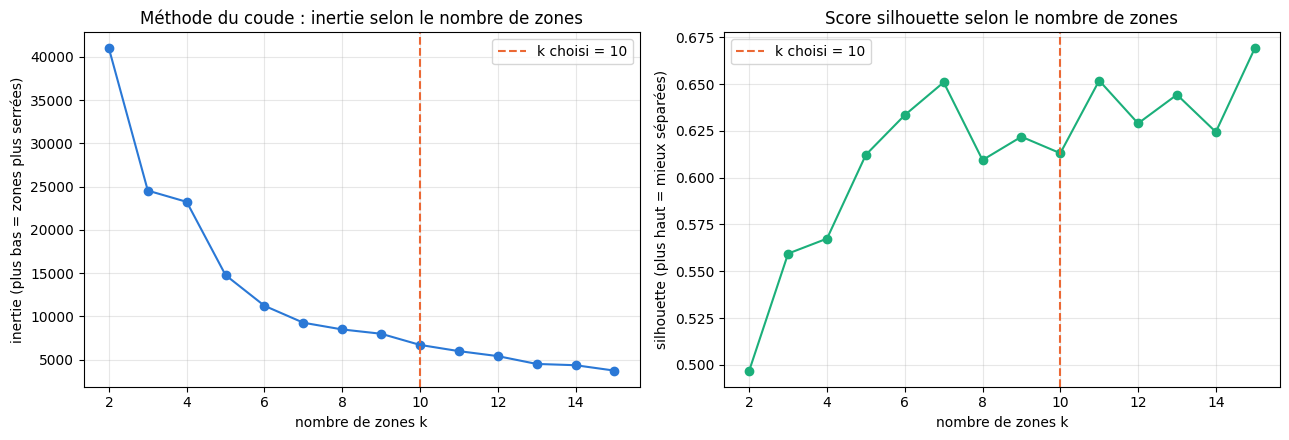

In [7]:
import matplotlib.pyplot as plt

valeurs_k = list(range(2, 16))
inerties = []
silhouettes = []
for k in valeurs_k:
    m = KMeans(k=k, seed=42, featuresCol="features", predictionCol="zone").fit(donnees)
    inerties.append(m.summary.trainingCost)
    silhouettes.append(evaluateur.evaluate(m.transform(donnees)))
    print(f"k = {k:2d}   inertie = {inerties[-1]:8.1f}   silhouette = {silhouettes[-1]:.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

ax1.plot(valeurs_k, inerties, marker="o", color="#2a78d6")
ax1.axvline(K, color="#eb6834", linestyle="--", label=f"k choisi = {K}")
ax1.set_title("Méthode du coude : inertie selon le nombre de zones")
ax1.set_xlabel("nombre de zones k")
ax1.set_ylabel("inertie (plus bas = zones plus serrées)")
ax1.legend()
ax1.grid(alpha=0.3)

ax2.plot(valeurs_k, silhouettes, marker="o", color="#1baf7a")
ax2.axvline(K, color="#eb6834", linestyle="--", label=f"k choisi = {K}")
ax2.set_title("Score silhouette selon le nombre de zones")
ax2.set_xlabel("nombre de zones k")
ax2.set_ylabel("silhouette (plus haut = mieux séparées)")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## 7. Je décris chaque zone
Pour chaque zone je calcule : le nombre de séismes, la magnitude moyenne et max, la profondeur moyenne, la part de séismes profonds (plus de 300 km), le centre de la zone, et la région qui revient le plus souvent dans la colonne lieu.

In [8]:
# la région = ce qu'il y a après la dernière virgule dans "lieu" (ex : "10 km SW of Tokyo, Japan" -> "Japan")
avec_region = resultat.withColumn("region", F.trim(F.element_at(F.split("lieu", ", "), -1)))

# la région la plus fréquente de chaque zone
fenetre = Window.partitionBy("zone").orderBy(F.desc("nb"))
region_principale = (
    avec_region.groupBy("zone", "region").agg(F.count("*").alias("nb"))
    .withColumn("rang", F.row_number().over(fenetre))
    .filter(F.col("rang") == 1)
    .select("zone", F.col("region").alias("region_principale"))
)

# le centre de la zone : je fais la moyenne de x, y, z puis je reconvertis en latitude et longitude
zones = (
    resultat.groupBy("zone")
    .agg(
        F.count("*").alias("nb_seismes"),
        F.round(F.avg("magnitude"), 2).alias("mag_moyenne"),
        F.max("magnitude").alias("mag_max"),
        F.round(F.avg("profondeur"), 0).alias("profondeur_moyenne"),
        F.round(F.avg(F.when(F.col("profondeur") > 300, 1).otherwise(0)) * 100, 1).alias("pct_profonds"),
        F.avg("x").alias("cx"), F.avg("y").alias("cy"), F.avg("z").alias("cz"),
    )
    .withColumn("centre_latitude", F.round(F.degrees(F.atan2("cz", F.sqrt(F.col("cx") ** 2 + F.col("cy") ** 2))), 1))
    .withColumn("centre_longitude", F.round(F.degrees(F.atan2("cy", "cx")), 1))
    .drop("cx", "cy", "cz")
    .join(region_principale, "zone")
    .orderBy(F.desc("nb_seismes"))
)

zones.show(truncate=False)

total = zones.agg(F.sum("nb_seismes")).first()[0]
print("Somme des zones :", total, "| attendu : 74362 |", total == 74362)

+----+----------+-----------+-------+------------------+------------+---------------+----------------+-----------------------------+
|zone|nb_seismes|mag_moyenne|mag_max|profondeur_moyenne|pct_profonds|centre_latitude|centre_longitude|region_principale            |
+----+----------+-----------+-------+------------------+------------+---------------+----------------+-----------------------------+
|0   |16364     |4.78       |7.8    |60.0              |2.4         |6.6            |126.1           |Indonesia                    |
|4   |14902     |4.82       |8.2    |124.0             |18.1        |-26.7          |179.9           |Tonga                        |
|3   |9616      |4.82       |8.8    |44.0              |2.2         |46.8           |154.9           |Russia                       |
|1   |9193      |4.81       |8.2    |61.0              |0.8         |-6.8           |-82.1           |Chile                        |
|7   |6890      |4.83       |7.9    |57.0              |1.1         |

Somme des zones : 74362 | attendu : 74362 | True


## 7 bis. Les 10 zones sur une carte
Chaque point est un séisme, avec la couleur de sa zone. Les croix noires sont les centres des zones, avec le numéro de la zone et sa région principale.
Je n'ai pas de fond de carte, mais on reconnaît quand même les contours des plaques : ce sont les séismes qui les dessinent.

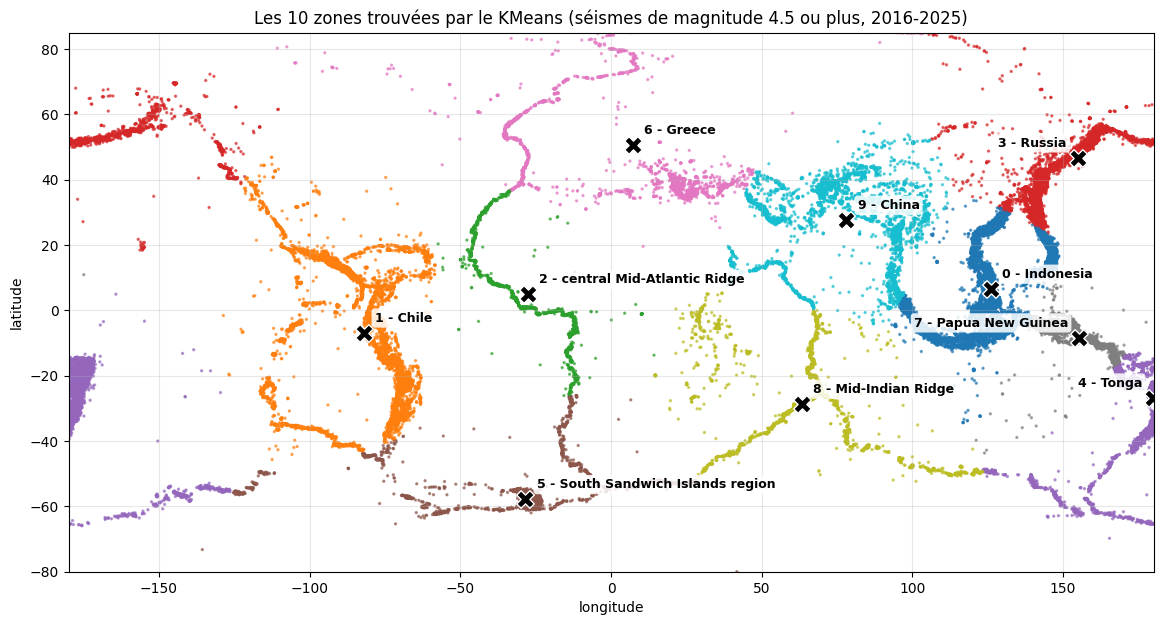

In [9]:
points_pd = resultat.select("longitude", "latitude", "zone").toPandas()
zones_pd = zones.toPandas()

fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter(points_pd["longitude"], points_pd["latitude"], c=points_pd["zone"],
           cmap="tab10", vmin=0, vmax=9, s=2, alpha=0.6)

for _, z in zones_pd.iterrows():
    ax.scatter(z["centre_longitude"], z["centre_latitude"], marker="X", s=160,
               color="black", edgecolor="white", linewidth=1)
    # près du bord droit de la carte, j'écris le nom à gauche de la croix pour qu'il ne soit pas coupé
    a_gauche = z["centre_longitude"] > 140
    ax.annotate(f"{z['zone']} - {z['region_principale']}",
                (z["centre_longitude"], z["centre_latitude"]),
                xytext=(-8, 8) if a_gauche else (8, 8), textcoords="offset points",
                ha="right" if a_gauche else "left", fontsize=9, fontweight="bold",
                bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.85, edgecolor="none"))

ax.set_xlim(-180, 180)
ax.set_ylim(-80, 85)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title(f"Les {K} zones trouvées par le KMeans (séismes de magnitude 4.5 ou plus, 2016-2025)")
ax.grid(alpha=0.3)
plt.show()

## 7 ter. Je compare les zones entre elles
À gauche : combien de séismes dans chaque zone. À droite : la part de séismes profonds (plus de 300 km).
Je garde les mêmes couleurs que sur la carte pour retrouver chaque zone.

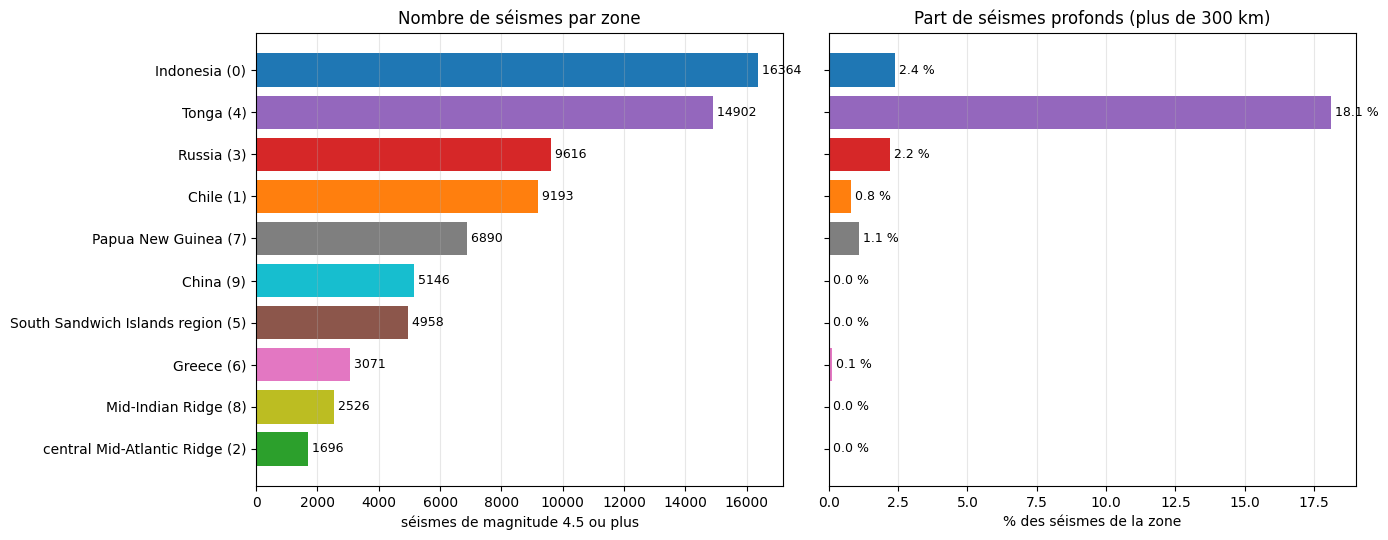

In [10]:
zones_tri = zones_pd.sort_values("nb_seismes")
noms = [f"{r} ({z})" for z, r in zip(zones_tri["zone"], zones_tri["region_principale"])]
couleurs = [plt.cm.tab10(z) for z in zones_tri["zone"]]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True)

ax1.barh(noms, zones_tri["nb_seismes"], color=couleurs)
for i, v in enumerate(zones_tri["nb_seismes"]):
    ax1.text(v, i, f" {v}", va="center", fontsize=9)
ax1.set_title("Nombre de séismes par zone")
ax1.set_xlabel("séismes de magnitude 4.5 ou plus")
ax1.grid(axis="x", alpha=0.3)

ax2.barh(noms, zones_tri["pct_profonds"], color=couleurs)
for i, v in enumerate(zones_tri["pct_profonds"]):
    ax2.text(v, i, f" {v} %", va="center", fontsize=9)
ax2.set_title("Part de séismes profonds (plus de 300 km)")
ax2.set_xlabel("% des séismes de la zone")
ax2.grid(axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

## Ce que je remarque
- Le score silhouette de 0.613 montre que les zones sont plutôt bien séparées.
- Le KMeans ne connaît pas la géologie, mais il retrouve quand même les grandes régions sismiques : Indonésie, Tonga, Kamtchatka (Russie), Chili, Papouasie-Nouvelle-Guinée...
- La zone Tonga a 18.1 % de séismes profonds, alors que toutes les autres en ont moins de 3 % : c'est là que la plaque plonge le plus profondément (zone de subduction).
- Les deux zones des dorsales (milieu de l'Atlantique et de l'océan Indien) ont une profondeur moyenne de 10 km : ce sont des séismes superficiels, là où les plaques s'écartent.
- Sur la carte, la zone Tonga apparaît aux deux bords (à +180° et à -180°) mais reste une seule zone : c'est grâce à la conversion en x, y, z de l'étape 4.
- Limite : le KMeans fait des groupes "ronds" autour d'un centre, il ne suit pas la forme allongée des frontières de plaques. Par exemple, la zone "Chile" regroupe toute la côte ouest de l'Amérique, du Mexique jusqu'au Chili.

## 8. J'enregistre les zones dans une table gold et dans la couche de service
- gold_zones : le résumé des 10 zones (une ligne par zone)
- gold_carte_zones : pour chaque séisme, le numéro de sa zone (pour colorier la carte du dashboard)

In [11]:
zones.coalesce(1).write.format("delta").mode("overwrite").save(CHEMIN_ZONES)
print("gold_zones écrite :", spark.read.format("delta").load(CHEMIN_ZONES).count(), "lignes")

zones_pd = zones.toPandas()
zones_pd.to_parquet(DOSSIER_SERVING / "gold_zones.parquet", index=False)

carte_zones_pd = resultat.select("id", "zone").toPandas()
carte_zones_pd.to_parquet(DOSSIER_SERVING / "gold_carte_zones.parquet", index=False)

print("gold_zones.parquet       :", len(zones_pd), "lignes")
print("gold_carte_zones.parquet :", len(carte_zones_pd), "lignes")

gold_zones écrite : 10 lignes
gold_zones.parquet       : 10 lignes
gold_carte_zones.parquet : 74362 lignes


## 9. Je libère le cache et je ferme la SparkSession

In [12]:
donnees.unpersist()
resultat.unpersist()
spark.stop()